# 03 · Tabular models

**Purpose.** Find out whether machine learning on **tabular data** (inspection history, violation mix, ownership, 311 activity, neighbourhood patterns) produces a better priority list than the best simple rule. This closes Phase 1.

**The bar (notebook 02).** *Rule 1 · previous inspection*, the simple no-ML rule we proposed ("go back first to the places whose previous routine inspection found a Priority violation or failed"), already captures a large share of the possible gain (37% in 2024). **Exit criterion:** the best model beats Rule 1 on the pooled 2022–24 backtest by **≥ 3 extra hits per 100 visits**, with a 95% CI excluding zero.

**What this notebook tries**

| # | Experiment | Question |
|---|---|---|
| E1 | Logistic regression | How far does a simple linear model get? |
| E2 | LightGBM, default settings | Do non-linear interactions help? |
| E3 | LightGBM, tuned | How much does tuning add? |
| E4 | LightGBM ranker (lambdarank by month) | Does optimising the *ranking* directly beat predicting probabilities? |
| E5 | Longer training window (2012+) | Does more data with an older label definition help? |
| E6 | Feature-group ablation | Which information actually matters? |

**Risks checked:** R13 violation-code eras · R14 as-of leakage · R25 *decision-time leakage* (new, explained in §1) · R11 precision · R12 drift · R23 reproducibility. The test period (2025–26) stays locked.

## 0 · Setup

In [1]:
import warnings
from datetime import date

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score

from inspections import config, features, models
from inspections.checks import CheckLog
from inspections.metrics import bootstrap_diff, capture_curve, days_earlier, hit_rate, per_month

warnings.filterwarnings('ignore', category=UserWarning)
pd.set_option('display.width', 160)
BACKTEST_YEARS = [2022, 2023, 2024]

visits = pd.read_parquet(config.PROCESSED / 'visits.parquet')
violations = pd.read_parquet(config.PROCESSED / 'violations.parquet')
licenses = pd.read_parquet(config.PROCESSED / 'licenses.parquet')
complaints = pd.read_parquet(config.PROCESSED / 'complaints.parquet')
print(f'lightgbm {lgb.__version__} · {len(visits):,} visits · {len(violations):,} violations · {len(complaints):,} 311 cases')

lightgbm 4.7.0 · 193,852 visits · 835,847 violations · 67,320 311 cases


**From the package (`src/inspections/`):** the metric helpers of notebook 02 and the `check()` helper.

In [2]:
# the metric helpers come from src/inspections/metrics.py (imported above)
CHECKS = CheckLog()
check = CHECKS.check

## 1 · When is the list made? Decision-time features (R25)

The priority list for a month is drawn up **before the month starts**, so a feature may only use what is known at that moment. Every feature is computed **as of the first day of the visit's month (`t0`)**, using only events strictly before `t0`.

This is stricter than "before the visit": measured on the actual visit date, "days since the last visit" would encode the very visit order we're trying to improve (notebook 02 §3). For the same reason **visit-day weather is not used**; month-of-year carries seasonality. Notebook 02's rules use the same decision time, so the comparison is like for like.

## 2 · Feature construction

### 2.1 Violation types, mapped across both Food Code eras (R13)

The violation codes changed in 2019, so codes can't be compared across eras. We group the *descriptions* into eight types with keyword rules and check that the rules cover both eras.

In [3]:
group_of = {d: features.violation_group(d) for d in violations.violdesc.dropna().unique()}   # keyword map in features.py
violations['group'] = violations.violdesc.map(group_of).fillna('other')
era = np.where(violations.visit_ts.dt.year >= 2020, '2020+', 'before 2020')
mix = pd.crosstab(violations.group, era, normalize='columns')
coverage = 1 - mix.loc['other']
check('R13', 'keyword groups cover ≥95% of violations in both eras', (coverage >= .95).all(),
      ', '.join(f'{e}: {c:.1%}' for e, c in coverage.items()))
mix.style.format('{:.1%}')

✓ R13: keyword groups cover ≥95% of violations in both eras  [2020+: 96.0%, before 2020: 99.7%]


col_0,2020+,before 2020
group,,
contamination,17.5%,16.0%
facility,27.8%,28.3%
handwashing,9.2%,8.6%
management,6.0%,4.4%
other,4.0%,0.3%
pests,6.0%,3.9%
sanitizing,18.4%,29.0%
temperature,11.1%,9.5%


In [4]:
viol_groups = features.violation_group_counts(violations)
GROUP_COLS = list(viol_groups.columns)

### 2.2 The feature builder

Feature groups:

| Group | Features | Intuition |
|---|---|---|
| **history** | previous routine visit failed / severe / number of violations; second-to-last visit; lifetime fail and severe rates; follow-ups needed last cycle; ever escalated; days since last visit, last routine visit, last fail, first visit | past behaviour predicts future behaviour |
| **violation mix** | counts by type at the previous routine visit | temperature or pest problems recur more than cosmetic ones |
| **recent trend** | sums over the last 3 routine visits; recency-weighted (EWMA) fail and severe rates; severe rate under the new code only | is the place getting better or worse? |
| **owner** | number of routine visits and severe rate at the *same owner's other* licenses | operators run several places the same way |
| **311 nearby** | food complaints and rodent reports within 100 m, prior 90 / 365 days | local sanitation conditions |
| **area recent rates** | share of routine visits within 1 km (any establishment) that found a severe violation, or failed, in the prior 90 / 180 days | **stand-in for the unobserved inspector** (R-limitation): inspectors work by area, and strictness differs |
| **calendar & place** | license type, month of year, pandemic period, latitude / longitude | seasonality, type, geography |

Everything is computed by one function, **`build_features(rows, visits_src, complaints_src)`**, from the source tables it is given. That makes a strong leakage test possible (§2.3).

In [5]:
# The feature builders live in src/inspections/features.py. Notebook 03's settings: recent trend over the last 3 routine
# visits, recency weight 0.5, area columns named with their 1 km radius.
def build_features(rows, visits_src, complaints_src):
    """All features for `rows`, as of the first day of each row's month, using only the given source tables."""
    return features.build_phase1_features(rows, visits_src, complaints_src, viol_groups, licenses,
                                          area_name='area_{name}_1km_{days}d')

**Rows.** We build features for every routine visit from **2012 to 2024**, so experiment E5 can train on older years. Scoring and evaluation only ever use the 2020+ prediction set. **No test-period row is built at all.**

In [6]:
routine = visits.opener & ~visits.irregular & ~visits.complaint_driven
in_years = visits.visit_ts.dt.year.between(2012, 2024)
rows = visits[routine & in_years].copy()
check('R14', 'no test-period rows in the modelling table', rows.split.isin(['train', 'valid', 'history']).all(),
      f'{len(rows):,} rows, latest {rows.visit_ts.max():%Y-%m-%d}')

X, t0 = build_features(rows, visits, complaints)
y = rows.hit.to_numpy()
year = rows.visit_ts.dt.year.to_numpy()
print(f'feature matrix: {X.shape[0]:,} rows × {X.shape[1]} features')

✓ R14: no test-period rows in the modelling table  [70,931 rows, latest 2024-12-31]


feature matrix: 70,931 rows × 55 features


In [7]:
FEATURE_GROUPS = {
    'history': ['has_history', 'prev_fail', 'prev_severe', 'prev_n_viol', 'prev_n_severe', 'prev_old_code', 'prev2_fail',
                'prev2_severe', 'n_prior_routine', 'prior_fail_rate', 'prior_severe_rate', 'followups_last_cycle',
                'ever_escalated', 'last_visit_filed', 'days_since_last_visit', 'days_since_last_routine',
                'days_since_last_fail', 'days_since_first_visit'],
    'violation mix': [f'prev_{c}' for c in GROUP_COLS],
    'recent trend': [c for c in X.columns if c.startswith('last3_')] + ['ewm_severe', 'ewm_fail', 'new_code_severe_rate'],
    'owner': ['owner_known', 'owner_other_routine', 'owner_other_severe_rate'],
    '311 nearby': [c for c in X.columns if c.startswith(('food_complaints', 'rodent_reports'))],
    'area recent rates': [c for c in X.columns if c.startswith('area_')],
    'calendar & place': ['cat_FS', 'cat_FT', 'cat_RF', 'month_of_year', 'pandemic', 'lat', 'lon'],
}
assigned = sum(FEATURE_GROUPS.values(), [])
assert sorted(assigned) == sorted(X.columns), set(X.columns) ^ set(assigned)
pd.DataFrame({g: {'features': len(c), 'share missing (mean)': X[c].isna().mean().mean()} for g, c in FEATURE_GROUPS.items()}).T \
  .style.format({'features': '{:.0f}', 'share missing (mean)': '{:.1%}'})

,features,share missing (mean)
history,18,6.9%
violation mix,8,6.4%
recent trend,9,13.2%
owner,3,38.3%
311 nearby,4,9.5%
area recent rates,6,9.6%
calendar & place,7,2.7%


Missing values come from first-ever visits (no history), licenses without coordinates (about 10%), and owners not recorded (about half). LightGBM handles missing values natively; logistic regression gets median imputation plus missing-indicators.

### 2.3 Leakage tests (R14, R25)

**Test 1, truncation.** Rebuild the features from source tables cut off at 1 July 2023: every visit and complaint on or after that date is deleted. For every row whose decision date `t0` is on or before the cut-off, the features **must be identical** to the full build. If any feature looked into the future, it would change.

In [8]:
CUTOFF = pd.Timestamp('2023-07-01')
probe = rows[(t0 >= '2023-01-01') & (t0 <= CUTOFF)]
cut_tz = CUTOFF.tz_localize('America/New_York')
X_full, _ = build_features(probe, visits, complaints)
X_cut, _ = build_features(probe, visits[visits.visit_ts < cut_tz], complaints[complaints.open_ts < cut_tz])
same = np.isclose(X_full.to_numpy(), X_cut.to_numpy(), equal_nan=True)
check('R14', 'features identical when all data after the decision date is deleted', same.all(),
      f'{len(probe):,} rows × {X.shape[1]} features; mismatches: {(~same).sum()}')

✓ R14: features identical when all data after the decision date is deleted  [3,205 rows × 55 features; mismatches: 0]


**Test 2, decision time.** The latest visit and the latest routine visit used for any row must be strictly earlier than the first day of its month. This compares the actual timestamps: a whole-day count would show 0 for a visit on the evening before the month starts.

In [9]:
keys = rows[['licenseno']].assign(t0=t0)
v_hist, o_hist = features.history_tables(visits, viol_groups, ewm_alpha=0.5, last_n=3)
last_visit = features.asof(keys, v_hist[['licenseno', 'ts']], 'ts', 'licenseno').ts
last_routine = features.asof(keys, o_hist[['licenseno', 'ts']], 'ts', 'licenseno').ts
ok = (last_visit.dropna() < t0[last_visit.notna()]).all() and (last_routine.dropna() < t0[last_routine.notna()]).all()
check('R25', 'every history input predates the start of the visit month', bool(ok),
      f'closest gap: {(t0 - last_visit).min()}')

✓ R25: every history input predates the start of the visit month  [closest gap: 0 days 13:49:39]


## 3 · Evaluation design: rolling backtest

One validation year gives wide intervals (notebook 02), so models are compared on a **rolling backtest**:

| Fold | Train on | Predict |
|---|---|---|
| 1 | 2020–2021 | 2022 |
| 2 | 2020–2022 | 2023 |
| 3 | 2020–2023 | 2024 |

The three out-of-sample years (36 months, about 17,000 routine visits) are pooled for every metric. Each model is retrained from scratch per fold, as it would be in practice.

The comparators are recomputed **at decision time** from the same feature table: current practice (the city's actual order), Rule 1 (previous inspection) and the oracle. Rule 2 is left out because notebook 02 showed it is weaker than Rule 1.

In [10]:
in_eval = rows.in_prediction_set.to_numpy() & np.isin(year, BACKTEST_YEARS)
ev = rows.loc[in_eval, ['month', 'visit_ts', 'hit', 'category']].copy()
ev['tiebreak'] = np.random.default_rng(config.SEED).random(len(ev))
ev['actual'] = -ev.visit_ts.dt.tz_localize(None).astype('int64')
ev['oracle'] = ev.hit.astype(int)
Xe = X.loc[ev.index]
ev['rule1'] = features.rule1_score(Xe)
PM = {name: per_month(ev, col) for name, col in [('current', 'actual'), ('rule1', 'rule1'), ('oracle', 'oracle')]}
print(f'backtest pool: {len(ev):,} visits · {ev.month.nunique()} months · hit rate {ev.hit.mean():.1%}')
print(f"HR@50  current {hit_rate(PM['current']):.1%} · Rule 1 {hit_rate(PM['rule1']):.1%} · oracle {hit_rate(PM['oracle']):.1%}")

backtest pool: 17,354 visits · 36 months · hit rate 21.6%
HR@50  current 21.5% · Rule 1 31.0% · oracle 43.2%


In [11]:
RESULTS = {}

def evaluate(name, score, note=''):
    """Score a set of out-of-sample predictions (indexed like `ev`) and add them to the leaderboard."""
    ev[name] = score.loc[ev.index].to_numpy()
    pm = per_month(ev, name)
    hr, base, b1, orc = hit_rate(pm), hit_rate(PM['current']), hit_rate(PM['rule1']), hit_rate(PM['oracle'])
    lo, hi = bootstrap_diff(pm, PM['rule1'])
    RESULTS[name] = {'HR@50': hr, 'vs current (per 100)': 100 * (hr - base), 'vs Rule 1 (per 100)': 100 * (hr - b1),
                     'vs Rule 1 95% CI': f'[{100 * lo:+.1f}, {100 * hi:+.1f}]', 'headroom captured': (hr - base) / (orc - base),
                     'days earlier': days_earlier(ev, name), 'PR-AUC': average_precision_score(ev.hit, ev[name]),
                     'ROC-AUC': roc_auc_score(ev.hit, ev[name]), 'note': note}
    return pd.Series(RESULTS[name]).to_frame(name).T

def leaderboard():
    return (pd.DataFrame(RESULTS).T.style
            .format({'HR@50': '{:.1%}', 'vs current (per 100)': '{:+.1f}', 'vs Rule 1 (per 100)': '{:+.1f}',
                     'headroom captured': '{:.0%}', 'days earlier': '{:.1f}', 'PR-AUC': '{:.3f}', 'ROC-AUC': '{:.3f}'}))

evaluate('Rule 1 · previous inspection', ev['rule1'], 'our no-ML rule, no training')

,HR@50,vs current (per 100),vs Rule 1 (per 100),vs Rule 1 95% CI,headroom captured,days earlier,PR-AUC,ROC-AUC,note
Rule 1 · previous inspection,0.309529,9.494693,0.0,"[+0.0, +0.0]",0.437069,4.050286,0.349922,0.674191,"our no-ML rule, no training"


In [12]:
def backtest(make_model, features, train_from=2020, label=y):
    """Out-of-sample predictions for each backtest year, training on [train_from, year)."""
    oof = pd.Series(np.nan, index=rows.index)
    Xf = X[features]
    for Y in BACKTEST_YEARS:
        tr = (year >= train_from) & (year < Y)
        if train_from >= 2020:                     # clean-label runs train on the prediction set only
            tr &= rows.in_prediction_set.to_numpy()
        te = year == Y
        model = make_model()
        model.fit(Xf[tr], label[tr])
        oof[te] = model.predict_proba(Xf[te])[:, 1]
    return oof

ALL = list(X.columns)

## 4 · Experiments

### E1 · Logistic regression

A regularised linear model on all features, with median imputation, missing-indicators and standardisation. If this already clears the bar, there is no case for anything more complex.

In [13]:
def make_logreg():
    return models.make_logreg(C=0.1)

oof_lr = backtest(make_logreg, ALL)
evaluate('E1 · logistic regression', oof_lr, 'all features, L2, C=0.1')

,HR@50,vs current (per 100),vs Rule 1 (per 100),vs Rule 1 95% CI,headroom captured,days earlier,PR-AUC,ROC-AUC,note
E1 · logistic regression,0.338256,12.367328,2.872635,"[+2.3, +3.4]",0.569304,5.809797,0.455952,0.751996,"all features, L2, C=0.1"


### E2 · LightGBM, default settings

Gradient-boosted trees capture interactions (e.g. "failed last time *and* in a strict area") and thresholds without manual feature engineering.

In [14]:
def make_lgb(**params):
    base = dict(n_estimators=400, learning_rate=0.03, num_leaves=31, min_child_samples=20, subsample=0.8,
                subsample_freq=1, colsample_bytree=0.8, random_state=config.SEED, verbose=-1)
    base.update(params)
    return lambda: lgb.LGBMClassifier(**base)

oof_lgb = backtest(make_lgb(), ALL)
evaluate('E2 · LightGBM default', oof_lgb, '31 leaves, 400 trees')

,HR@50,vs current (per 100),vs Rule 1 (per 100),vs Rule 1 95% CI,headroom captured,days earlier,PR-AUC,ROC-AUC,note
E2 · LightGBM default,0.331564,11.6982,2.203507,"[+1.6, +2.8]",0.538502,5.565016,0.441307,0.741481,"31 leaves, 400 trees"


### E3 · LightGBM, tuned

Random search over 16 configurations. **Each configuration is scored only on folds 1–2 (predicting 2022 and 2023)**, by PR-AUC, a smooth ranking measure. The winner is then run through the full backtest.

*Caveat:* folds 1–2 also count in the pooled leaderboard, so E3 is slightly flattered. Fold 3 (2024) was never used for selection, so it is reported separately below as the clean check.

In [15]:
space = dict(num_leaves=[7, 15, 31], min_child_samples=[50, 100, 200, 400], learning_rate=[0.01, 0.02, 0.05],
             n_estimators=[300, 600, 1000], colsample_bytree=[0.5, 0.8], reg_lambda=[0, 1, 5, 20])
r = np.random.default_rng(config.SEED)
trials = []
for t in range(16):
    params = {k: v[r.integers(len(v))] for k, v in space.items()}
    scores = []
    for Y in [2022, 2023]:
        tr = (year >= 2020) & (year < Y) & rows.in_prediction_set.to_numpy()
        te = (year == Y) & in_eval
        m = make_lgb(**params)().fit(X.loc[tr, ALL], y[tr])
        scores.append(average_precision_score(y[te], m.predict_proba(X.loc[te, ALL])[:, 1]))
    trials.append({**params, 'PR-AUC (folds 1–2)': np.mean(scores)})
trials = pd.DataFrame(trials).sort_values('PR-AUC (folds 1–2)', ascending=False)
BEST = trials.iloc[0].drop('PR-AUC (folds 1–2)').to_dict()
BEST = {k: (int(v) if k in ('num_leaves', 'min_child_samples', 'n_estimators') else float(v)) for k, v in BEST.items()}
print('best configuration:', BEST)
trials.head(6).style.format({'PR-AUC (folds 1–2)': '{:.4f}'})

best configuration: {'num_leaves': 31, 'min_child_samples': 50, 'learning_rate': 0.01, 'n_estimators': 300, 'colsample_bytree': 0.8, 'reg_lambda': 0.0}


,num_leaves,min_child_samples,learning_rate,n_estimators,colsample_bytree,reg_lambda,PR-AUC (folds 1–2)
7,31,50,0.010000,300,0.800000,0,0.4778
8,7,200,0.020000,300,0.800000,5,0.4772
2,7,50,0.010000,600,0.800000,20,0.4768
12,15,400,0.010000,600,0.500000,0,0.4767
4,31,200,0.010000,300,0.500000,20,0.4764
0,31,400,0.010000,300,0.800000,0,0.4761


In [16]:
oof_tuned = backtest(make_lgb(**BEST), ALL)
evaluate('E3 · LightGBM tuned', oof_tuned, 'random search on folds 1–2')

,HR@50,vs current (per 100),vs Rule 1 (per 100),vs Rule 1 95% CI,headroom captured,days earlier,PR-AUC,ROC-AUC,note
E3 · LightGBM tuned,0.335487,12.090448,2.595754,"[+2.0, +3.2]",0.556559,5.830055,0.457519,0.752841,random search on folds 1–2


**The search surface is flat:** the top six configurations are within 0.002 PR-AUC of each other, and the winner is simply a cautious model (low learning rate, 300 trees). Tuning can't find much extra signal, a first hint that the information, not the model, is the limit.

### E4 · LightGBM ranker

The decision is a **ranking within each month**, so rather than predicting probabilities we can optimise the ranking directly. LightGBM's `lambdarank` objective learns to order visits within groups, here each month.

In [17]:
def backtest_ranker(params, features):
    oof = pd.Series(np.nan, index=rows.index)
    for Y in BACKTEST_YEARS:
        tr = (year >= 2020) & (year < Y) & rows.in_prediction_set.to_numpy()
        te = year == Y
        order = np.argsort(rows.month.to_numpy()[tr], kind='stable')
        Xtr, ytr = X.loc[tr, features].iloc[order], y[tr][order]
        groups = pd.Series(rows.month.to_numpy()[tr][order]).value_counts(sort=False).reindex(
            pd.unique(rows.month.to_numpy()[tr][order])).to_numpy()
        ranker = lgb.LGBMRanker(objective='lambdarank', lambdarank_truncation_level=1000, **params,
                                random_state=config.SEED, verbose=-1)
        ranker.fit(Xtr, ytr.astype(int), group=groups)
        oof[te] = ranker.predict(X.loc[te, features])
    return oof

rank_params = {k: v for k, v in BEST.items()}
oof_rank = backtest_ranker(rank_params, ALL)
evaluate('E4 · LightGBM ranker', oof_rank, 'lambdarank, groups = months')

,HR@50,vs current (per 100),vs Rule 1 (per 100),vs Rule 1 95% CI,headroom captured,days earlier,PR-AUC,ROC-AUC,note
E4 · LightGBM ranker,0.336179,12.159668,2.664975,"[+2.1, +3.2]",0.559745,5.828424,0.458155,0.753046,"lambdarank, groups = months"


### E5 · Longer training window (2012+)

From 2012 there are about twice as many training rows, but before 2020 "severe" followed the older definition (notebook 01). Does the extra data outweigh the noisier labels? The model sees `prev_old_code` and the calendar, and we add an explicit *old-label* flag for the row itself.

In [18]:
X['label_old_code'] = (year < 2020).astype(float)
oof_long = backtest(make_lgb(**BEST), ALL + ['label_old_code'], train_from=2012)
X = X.drop(columns='label_old_code')
evaluate('E5 · LightGBM tuned, train 2012+', oof_long, 'more data, older label definition flagged')

,HR@50,vs current (per 100),vs Rule 1 (per 100),vs Rule 1 95% CI,headroom captured,days earlier,PR-AUC,ROC-AUC,note
"E5 · LightGBM tuned, train 2012+",0.337217,12.263498,2.768805,"[+2.2, +3.4]",0.564525,5.962396,0.460124,0.758359,"more data, older label definition flagged"


Note: in E5 the flag is 1 for pre-2020 *training* rows and 0 for every predicted row (all 2022+), so the model learns the old/new label shift and predicts under today's definition.

### Leaderboard

In [19]:
leaderboard()

,HR@50,vs current (per 100),vs Rule 1 (per 100),vs Rule 1 95% CI,headroom captured,days earlier,PR-AUC,ROC-AUC,note
Rule 1 · previous inspection,31.0%,+9.5,+0.0,"[+0.0, +0.0]",44%,4.1,0.350,0.674,"our no-ML rule, no training"
E1 · logistic regression,33.8%,+12.4,+2.9,"[+2.3, +3.4]",57%,5.8,0.456,0.752,"all features, L2, C=0.1"
E2 · LightGBM default,33.2%,+11.7,+2.2,"[+1.6, +2.8]",54%,5.6,0.441,0.741,"31 leaves, 400 trees"
E3 · LightGBM tuned,33.5%,+12.1,+2.6,"[+2.0, +3.2]",56%,5.8,0.458,0.753,random search on folds 1–2
E4 · LightGBM ranker,33.6%,+12.2,+2.7,"[+2.1, +3.2]",56%,5.8,0.458,0.753,"lambdarank, groups = months"
"E5 · LightGBM tuned, train 2012+",33.7%,+12.3,+2.8,"[+2.2, +3.4]",56%,6.0,0.460,0.758,"more data, older label definition flagged"


**Reading the leaderboard**
- **Every model beats Rule 1** by +2.2 to +2.9 hits per 100 visits, with CIs well clear of zero. Each finds hits about 1.5–2 days earlier than Rule 1 and captures about 55% of the headroom, vs 44% for Rule 1.
- **The simplest model is the best.** Logistic regression has the highest hit rate (33.8%) and is within noise of the best PR-AUC. Default LightGBM is the weakest model, and tuning, a ranking objective and a longer training window bring it back to roughly where logistic regression already is.
- So the signal is **largely additive**: risk rises steadily with a bad record and a strict area, without important interactions.

**Fold 3 only (2024, never used for tuning).** The cleanest comparison:

In [20]:
fold3 = ev.index[ev.visit_ts.dt.year == 2024]
ev3 = ev.loc[fold3]
pm3_b1 = per_month(ev3, 'rule1')
rows3 = {}
for name in RESULTS:
    col = 'rule1' if name.startswith('Rule 1') else name
    pm = per_month(ev3, col)
    lo, hi = bootstrap_diff(pm, pm3_b1)
    rows3[name] = {'HR@50 (2024)': hit_rate(pm), 'vs Rule 1 (per 100)': 100 * (hit_rate(pm) - hit_rate(pm3_b1)),
                   '95% CI': f'[{100 * lo:+.1f}, {100 * hi:+.1f}]'}
pd.DataFrame(rows3).T.style.format({'HR@50 (2024)': '{:.1%}', 'vs Rule 1 (per 100)': '{:+.1f}'})

,HR@50 (2024),vs Rule 1 (per 100),95% CI
Rule 1 · previous inspection,32.4%,+0.0,"[+0.0, +0.0]"
E1 · logistic regression,35.0%,+2.6,"[+1.8, +3.5]"
E2 · LightGBM default,34.6%,+2.2,"[+1.5, +3.2]"
E3 · LightGBM tuned,35.0%,+2.6,"[+1.7, +3.6]"
E4 · LightGBM ranker,35.0%,+2.6,"[+1.7, +3.5]"
"E5 · LightGBM tuned, train 2012+",35.0%,+2.6,"[+1.6, +3.7]"


### E6 · Which information matters? Feature-group ablation

Using the tuned LightGBM, we **remove one group at a time** and measure how much the pooled hit rate drops. A large drop means the group carries information the others don't.

In [21]:
ablation = {}
full_hr = RESULTS['E3 · LightGBM tuned']['HR@50']
full_ap = RESULTS['E3 · LightGBM tuned']['PR-AUC']
for group, cols in FEATURE_GROUPS.items():
    keep = [c for c in ALL if c not in cols]
    oof = backtest(make_lgb(**BEST), keep)
    ev['_tmp'] = oof.loc[ev.index].to_numpy()
    ablation[f'without {group}'] = {'HR@50': hit_rate(per_month(ev, '_tmp')),
                                    'change (per 100)': 100 * (hit_rate(per_month(ev, '_tmp')) - full_hr),
                                    'PR-AUC change': average_precision_score(ev.hit, ev._tmp) - full_ap}
only_hist = backtest(make_lgb(**BEST), FEATURE_GROUPS['history'])
ev['_tmp'] = only_hist.loc[ev.index].to_numpy()
ablation['history only'] = {'HR@50': hit_rate(per_month(ev, '_tmp')),
                            'change (per 100)': 100 * (hit_rate(per_month(ev, '_tmp')) - full_hr),
                            'PR-AUC change': average_precision_score(ev.hit, ev._tmp) - full_ap}
ev = ev.drop(columns='_tmp')
pd.DataFrame(ablation).T.sort_values('PR-AUC change').style.format(
    {'HR@50': '{:.1%}', 'change (per 100)': '{:+.1f}', 'PR-AUC change': '{:+.3f}'})

,HR@50,change (per 100),PR-AUC change
history only,33.0%,-0.6,-0.019
without area recent rates,33.2%,-0.4,-0.013
without history,33.3%,-0.3,-0.008
without 311 nearby,33.7%,+0.1,-0.003
without violation mix,33.5%,-0.0,-0.001
without owner,33.5%,-0.1,-0.001
without recent trend,33.7%,+0.1,-0.000
without calendar & place,33.4%,-0.2,+0.001


**Reading the ablation.** HR@50 changes are within about half a point, inside the noise, so PR-AUC is the steadier guide.
- **Area recent rates are the clearest single contribution** (−0.013 PR-AUC when removed). This supports the idea that local inspection intensity, most likely the inspector, shapes outcomes.
- **History information is spread over two groups** (history; recent trend), so removing either one is largely compensated by the other. "History only" loses the most overall (−0.019).
- Violation mix, owner, 311 and calendar features each add almost nothing on top. They could be dropped with little loss, which notebook 03b tests.

## 5 · The chosen model

**Choice: E1, logistic regression on the 2020+ window.** The plan's rule is *the simplest model within noise of the best*. Logistic regression has the highest hit rate and is within 0.004 of the best PR-AUC, and it is also the easiest to explain to the city and to audit. The tree models are kept as checks.

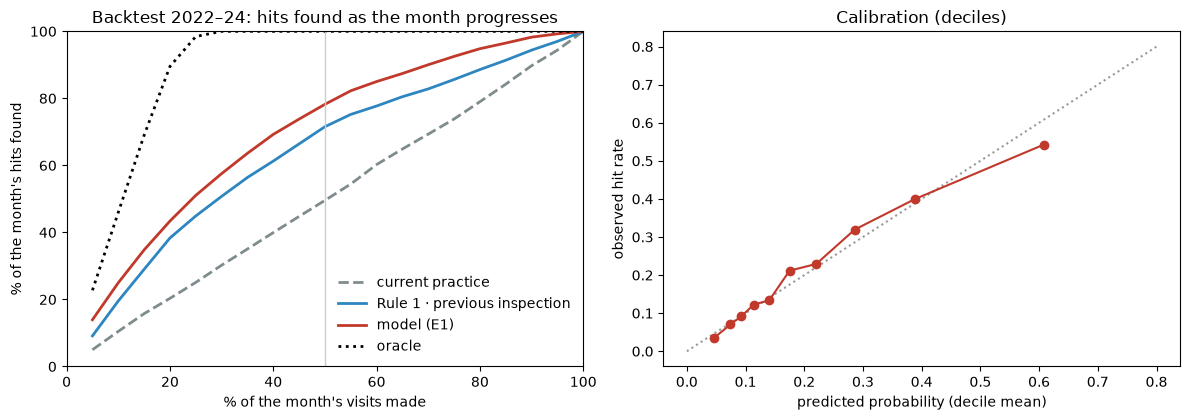

Brier score: model 0.1455 · always-predict-base-rate 0.1692


In [22]:
CHOSEN = 'E1 · logistic regression'
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))

grid = np.linspace(0.05, 1, 20)
for col, label, c, ls in [('actual', 'current practice', '#7f8c8d', '--'), ('rule1', 'Rule 1 · previous inspection', '#2e86c1', '-'),
                          (CHOSEN, 'model (E1)', '#c0392b', '-'), ('oracle', 'oracle', 'k', ':')]:
    axes[0].plot(100 * grid, 100 * capture_curve(ev, col, grid), ls, color=c, lw=2, label=label)
axes[0].axvline(50, color='#cccccc', lw=1)
axes[0].set(xlabel="% of the month's visits made", ylabel="% of the month's hits found", xlim=(0, 100), ylim=(0, 100),
            title='Backtest 2022–24: hits found as the month progresses')
axes[0].legend(frameon=False, loc='lower right')

prob = ev[CHOSEN]
bins = pd.qcut(prob, 10, duplicates='drop')
cal = ev.groupby(bins, observed=True).agg(predicted=(CHOSEN, 'mean'), observed=('hit', 'mean'))
axes[1].plot([0, .8], [0, .8], ':', color='#999999')
axes[1].plot(cal.predicted, cal.observed, 'o-', color='#c0392b')
axes[1].set(xlabel='predicted probability (decile mean)', ylabel='observed hit rate', title='Calibration (deciles)')
fig.tight_layout()
config.FIGURES.mkdir(parents=True, exist_ok=True)
fig.savefig(config.FIGURES / 'nb03_capture_and_calibration.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Brier score: model {brier_score_loss(ev.hit, prob):.4f} · always-predict-base-rate {brier_score_loss(ev.hit, np.full(len(ev), ev.hit.mean())):.4f}')

The capture curve sits above Rule 1 across the whole month, not just at the 50% mark. The calibration is close to the diagonal, so a score of 0.4 really does mean about a 40% chance of a Priority violation. That is useful when the list is shown to inspectors.

**Stability by year and license type:**

In [23]:
stab = {}
for Y in BACKTEST_YEARS:
    e = ev[ev.visit_ts.dt.year == Y]
    stab[Y] = {'current': hit_rate(per_month(e, 'actual')), 'Rule 1': hit_rate(per_month(e, 'rule1')),
               'model': hit_rate(per_month(e, CHOSEN)), 'oracle': hit_rate(per_month(e, 'oracle'))}
for cat in ['FS', 'FT', 'RF']:
    e = ev[ev.category == cat]
    stab[cat] = {'current': hit_rate(per_month(e, 'actual')), 'Rule 1': hit_rate(per_month(e, 'rule1')),
                 'model': hit_rate(per_month(e, CHOSEN)), 'oracle': hit_rate(per_month(e, 'oracle'))}
stab = pd.DataFrame(stab).T
stab['model − Rule 1 (per 100)'] = 100 * (stab.model - stab['Rule 1'])
stab.style.format('{:.1%}', subset=['current', 'Rule 1', 'model', 'oracle']).format('{:+.1f}', subset=['model − Rule 1 (per 100)'])

,current,Rule 1,model,oracle,model − Rule 1 (per 100)
2022,20.9%,31.3%,34.5%,44.2%,+3.2
2023,19.7%,29.1%,31.8%,38.5%,+2.8
2024,23.8%,32.4%,35.0%,46.5%,+2.6
FS,25.2%,35.1%,37.9%,51.7%,+2.8
FT,19.2%,28.6%,30.8%,38.9%,+2.2
RF,15.8%,20.8%,23.1%,28.8%,+2.3


## 6 · What drives the score?

Two views, both trained on 2020–2023 and explaining 2024:
- **left, the chosen logistic regression:** standardised coefficients (the change in log-odds per standard deviation of a feature);
- **right, the tuned LightGBM:** mean absolute SHAP values (built-in `pred_contrib`), a non-linear cross-check.

If both agree on what matters, we can trust the story.

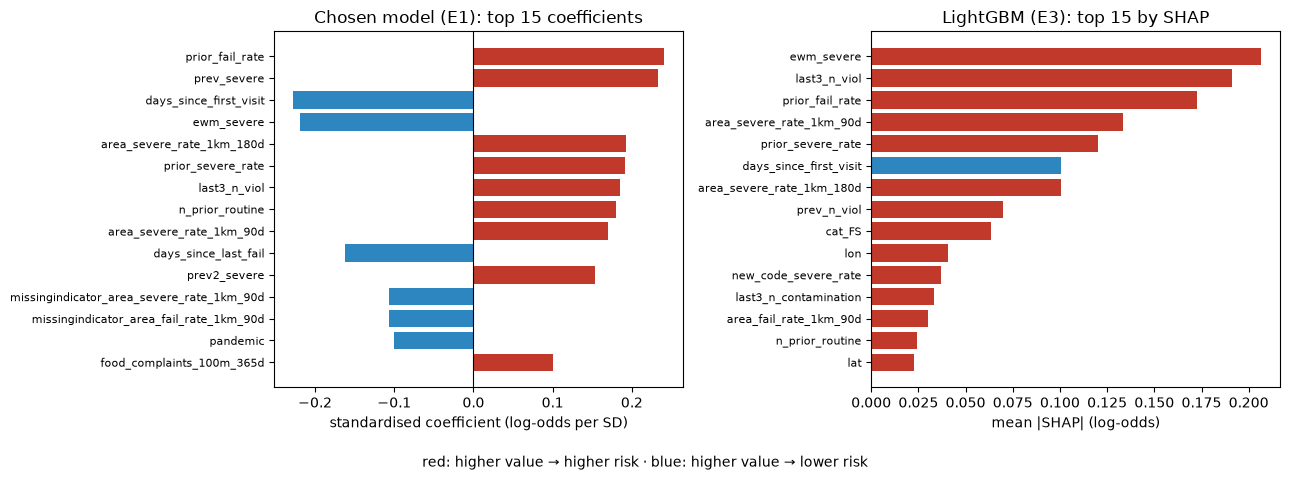

In [24]:
tr = (year >= 2020) & (year < 2024) & rows.in_prediction_set.to_numpy()
X24 = X.loc[ev.index[ev.visit_ts.dt.year == 2024], ALL]

logreg_2024 = make_logreg().fit(X.loc[tr, ALL], y[tr])
names = logreg_2024[0].get_feature_names_out(ALL)
coef = pd.Series(logreg_2024[-1].coef_[0], index=names)
coef = coef.reindex(coef.abs().sort_values(ascending=False).index).head(15)[::-1]

lgb_2024 = make_lgb(**BEST)().fit(X.loc[tr, ALL], y[tr])
contrib = pd.DataFrame(lgb_2024.predict(X24, pred_contrib=True)[:, :-1], columns=ALL, index=X24.index)
importance = contrib.abs().mean().sort_values(ascending=False).head(15)[::-1]
direction = pd.Series({c: np.corrcoef(X24[c].fillna(X24[c].median()), contrib[c])[0, 1] for c in importance.index})

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].barh(coef.index, coef.values, color=np.where(coef.values > 0, '#c0392b', '#2e86c1'))
axes[0].axvline(0, color='k', lw=.8)
axes[0].set(xlabel='standardised coefficient (log-odds per SD)', title='Chosen model (E1): top 15 coefficients')
axes[1].barh(importance.index, importance.values, color=['#c0392b' if direction[c] > 0 else '#2e86c1' for c in importance.index])
axes[1].set(xlabel='mean |SHAP| (log-odds)', title='LightGBM (E3): top 15 by SHAP')
for ax in axes:
    ax.tick_params(axis='y', labelsize=8)
fig.suptitle('red: higher value → higher risk · blue: higher value → lower risk', fontsize=10, y=0.02)
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig(config.FIGURES / 'nb03_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

**Both models tell the same story:**
- **The establishment's own record:** a recency-weighted severe-violation rate, the number of violations over the last visits, and the lifetime fail rate.
- **How strict inspections have recently been in its area:** the 90- and 180-day local severe rates.
- **Experience:** licenses seen for longer are lower-risk (blue).
- **Type:** sit-down restaurants (FS) are riskier.

**Reading the coefficients with care.** The history features are strongly correlated with each other (last visit severe, second-to-last severe, lifetime and recency-weighted severe rates), so logistic regression *splits* their weight. That is why `ewm_severe` gets a negative coefficient next to positive `prev_severe` and `prior_severe_rate`. Read them as a group ("a record of severe violations raises risk"), not one by one. The tree model, which isn't affected in the same way, ranks `ewm_severe` as its single strongest feature.

Other details: the *missing*-indicators for the area rates (establishments without coordinates) carry lower risk, and the pandemic period had fewer hits. Latitude and longitude appear in the tree model as location proxies; their colour has no simple meaning.

## 7 · Error analysis: which hits does the model miss?

A hit is **missed** if the model ranks it in the second half of its month. Comparing missed with found hits shows where more information would help.

In [25]:
ev['rank_pct'] = ev.groupby('month')[CHOSEN].rank(ascending=False, pct=True)
hits = ev[ev.hit].join(X[['has_history', 'prev_severe', 'prior_severe_rate', 'days_since_last_visit',
                          'area_severe_rate_1km_180d', 'owner_known']])
hits['found'] = hits.rank_pct <= .5
profile = hits.groupby('found').agg(hits=('hit', 'size'), first_visit=('has_history', lambda s: 1 - s.mean()),
                                    prev_visit_severe=('prev_severe', 'mean'), lifetime_severe_rate=('prior_severe_rate', 'mean'),
                                    days_since_last_visit=('days_since_last_visit', 'median'),
                                    area_severe_rate=('area_severe_rate_1km_180d', 'mean'))
profile.index = profile.index.map({True: 'found (first half)', False: 'missed (second half)'})
profile.style.format({'hits': '{:,}', 'first_visit': '{:.0%}', 'prev_visit_severe': '{:.0%}', 'lifetime_severe_rate': '{:.0%}',
                      'days_since_last_visit': '{:.0f}', 'area_severe_rate': '{:.0%}'})

,hits,first_visit,prev_visit_severe,lifetime_severe_rate,days_since_last_visit,area_severe_rate
found,,,,,,
missed (second half),811,13%,4%,15%,173,20%
found (first half),"2,932",0%,50%,44%,151,29%


In [26]:
first = ev.join(X['has_history'])
for label, sub in [('first-ever visits', first[first.has_history == 0]), ('repeat visits', first[first.has_history == 1])]:
    print(f'{label:18s}: {len(sub):5,} visits · hit rate {sub.hit.mean():.0%} · '
          f'share of their hits found in the first half: {(sub[sub.hit].rank_pct <= .5).mean():.0%}')

first-ever visits : 1,086 visits · hit rate 10% · share of their hits found in the first half: 8%
repeat visits     : 16,268 visits · hit rate 22% · share of their hits found in the first half: 81%


**Missed hits are mostly "surprises".** Only 4% of missed hits had a severe violation last time (vs 50% of found hits), and their lifetime severe rate is 15% vs 44%. Their records say low risk, so a history-based model rightly ranks them late. To catch them we need information that counts don't carry, such as *what* the inspector wrote ("repeat", "mice droppings", "no hot water"). That is Phase 2.

**First-ever visits** are rarely hits (10% vs 22%), so the model sensibly places them late. Only 8% of their hits land in the first half, and 13% of all missed hits are first visits.

## 8 · Secondary outcome: "the visit fails"

The same pipeline with the target swapped to *fail* (about 57% base rate), against the matching rule (failed last time first). This checks that our conclusions aren't an artefact of the target choice.

In [27]:
y_fail = rows.role.eq('fail').to_numpy()
oof_fail = backtest(make_lgb(**BEST), ALL, label=y_fail)
evf = ev[['month', 'visit_ts', 'tiebreak', 'actual']].copy()
evf['hit'] = y_fail[in_eval]
evf['rule'] = 2 * Xe.prev_fail.fillna(0) + Xe.prev_severe.fillna(0) + Xe.days_since_last_visit.fillna(9999) / 1e5
evf['model'] = oof_fail.loc[evf.index].to_numpy()
evf['oracle'] = evf.hit.astype(int)
pmf = {c: per_month(evf, c) for c in ['actual', 'rule', 'model', 'oracle']}
lo, hi = bootstrap_diff(pmf['model'], pmf['rule'])
print(f"fail target · HR@50: current {hit_rate(pmf['actual']):.1%} · rule {hit_rate(pmf['rule']):.1%} · "
      f"model {hit_rate(pmf['model']):.1%} · oracle {hit_rate(pmf['oracle']):.1%}")
print(f"model − rule: {100 * (hit_rate(pmf['model']) - hit_rate(pmf['rule'])):+.1f} per 100 visits, 95% CI [{100 * lo:+.1f}, {100 * hi:+.1f}]")

fail target · HR@50: current 56.4% · rule 71.1% · model 75.3% · oracle 98.7%
model − rule: +4.3 per 100 visits, 95% CI [+3.6, +5.0]


## 9 · Phase 1 exit check, and the experiment log

The criterion (notebook 02): the chosen model beats Rule 1 on the pooled backtest by **≥ 3 extra hits per 100 visits**, with a 95% CI excluding zero.

In [28]:
res = RESULTS[CHOSEN]
lo = float(res['vs Rule 1 95% CI'].strip('[]').split(',')[0])
gain = res['vs Rule 1 (per 100)']
print(f'{CHOSEN}: {gain:+.1f} extra hits per 100 visits vs Rule 1, 95% CI {res["vs Rule 1 95% CI"]}')
print(f'exit criterion (≥ +3.0 and CI excluding zero): {"MET" if gain >= 3 and lo > 0 else "NOT MET"}')

E1 · logistic regression: +2.9 extra hits per 100 visits vs Rule 1, 95% CI [+2.3, +3.4]
exit criterion (≥ +3.0 and CI excluding zero): NOT MET


In [29]:
log = pd.DataFrame(RESULTS).T.reset_index(names='experiment')
log.insert(0, 'date', date.today().isoformat())
log.insert(1, 'notebook', '03_tabular_models')
log['params'] = log.experiment.map({'E3 · LightGBM tuned': str(BEST), 'E5 · LightGBM tuned, train 2012+': str(BEST),
                                   'E4 · LightGBM ranker': str(BEST)}).fillna('')
path = config.RESULTS / 'experiments.csv'
config.RESULTS.mkdir(exist_ok=True)
previous = pd.read_csv(path) if path.exists() else pd.DataFrame()
if len(previous):
    previous = previous[previous.notebook != '03_tabular_models']    # re-running replaces this notebook's rows
pd.concat([previous, log], ignore_index=True).to_csv(path, index=False)
print(f'wrote {len(log)} rows for this notebook to {path.relative_to(config.ROOT)}')
pd.DataFrame(CHECKS)

wrote 6 rows for this notebook to results/experiments.csv


,risk,check,result,detail
0,R13,keyword groups cover ≥95% of violations in bot...,pass,"2020+: 96.0%, before 2020: 99.7%"
1,R14,no test-period rows in the modelling table,pass,"70,931 rows, latest 2024-12-31"
2,R14,features identical when all data after the dec...,pass,"3,205 rows × 55 features; mismatches: 0"
3,R25,every history input predates the start of the ...,pass,closest gap: 0 days 13:49:39


## Findings

**Results (pooled backtest 2022–24, 17,354 routine visits, 36 months)**

| | First-half hit rate | Extra hits / 100 visits | Headroom captured | Hits found earlier |
|---|---|---|---|---|
| Current practice | 21.5% | — | 0% | — |
| Rule 1 · previous inspection | 31.0% | +9.5 vs current | 44% | 4.1 days |
| **E1 · logistic regression** | **33.8%** | **+12.4 vs current · +2.9 vs Rule 1 [+2.3, +3.4]** | **57%** | **5.8 days** |
| Oracle | 43.2% | +21.7 | 100% | — |

1. **ML beats the best rule, consistently but modestly.** +2.9 hits per 100 visits over Rule 1 (CI +2.3 to +3.4), positive in every year (+2.6 to +3.2) and every license type (+2.2 to +2.8). Hits are found about 1.7 days earlier than with Rule 1, and the scores are well calibrated.
2. **The simplest model is the best one.** Logistic regression matches or beats tuned trees, a ranking objective and a longer training window. The information, not the algorithm, is the limit.
3. **A new signal: local inspection intensity.** Recent severe-violation rates of *nearby* establishments are the clearest addition beyond an establishment's own record, consistent with inspector strictness varying by area. This affects interpretation and fairness: part of what the model predicts is *who is likely to inspect*, not only how the kitchen is run.
4. **Older labels don't help.** The 2012+ window is on par, so we keep the clean 2020+ window.
5. **What's left is mostly surprises:** hits at establishments with clean records. Counts can't see them coming; inspector notes might.
6. **Secondary outcome:** for "fail" the same model beats its matching rule by +4.3 per 100 visits, so the conclusions don't hinge on the target choice.
7. All leakage checks pass (truncation, decision time), and no test-period row was built.

**Exit criterion: not met.** +2.9 vs the +3.0 bar. The gain is real and statistically clear, but just under the margin we set in notebook 02.